# Chapter 46: The dimpled manifold

Checks [chapter 46](../../book/46-the-dimpled-manifold.md). The model is exactly the one of the theorems: a **dimpled function**
`profile(position) + slope * height` on a flat sheet, with `position` a real number and `height` the one direction off the sheet.
The profile is `sin(3 position) + 0.5 sin(position)`, which has slope limit `3.5`. Nothing is trained, so there is no
linear-in-weights question. Distances use the metric of the Lean file: the distance between two inputs is the larger of the position
gap and the height gap (the `max` of `Prod.dist_eq`), and the distance in the ambient space adds the label gap by Pythagoras (`distance_between_data_points_is_by_pythagoras`).
The nearest distance is computed numerically, without the theorem's formula, as described in the first code cell.
These are measurements, not proofs: the proofs are in `Dimple.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from scipy.optimize import minimize_scalar
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE, DATA
import matplotlib.pyplot as plt

use_style()
SEED = 46
PROFILE_SLOPE_LIMIT = 3.0 + 0.5          # sum of frequency * amplitude of the profile
GRID_COUNT = 200_000


def note_by_construction(label, detail=""):
    """Print a statement the code forces to be true. It is not a check and is not evidence."""
    print(f"[by construction, cannot fail] {label}" + (f"  ({detail})" if detail else ""))


def evaluate_profile(position):
    return np.sin(3.0 * position) + 0.5 * np.sin(position)


def evaluate_dimpled(position, height, slope):
    return evaluate_profile(position) + slope * height


def make_dimple(position, slope, label):
    """The input obtained by stepping straight off the sheet: same position, height (label - profile) / slope."""
    return position, (label - evaluate_profile(position)) / slope


def get_nearest_distance(position, label, slope):
    """
    Distance from the data point (position, height 0, label) to the graph of the dimpled function.

    A graph point (p, h, f) is at distance sqrt(r^2 + gap^2) where r = max(|p - position|, |h|) and gap = |f - label|.
    For a given r the values of f over the square |p - position| <= r, |h| <= r fill an interval (the square is connected):
    from (lowest profile value in the window) - slope * r to (highest profile value in the window) + slope * r.
    So the nearest distance is the minimum over r of sqrt(r^2 + gap(r)^2), with gap(r) the distance from the label to that
    interval. The radius is searched out to 1.3 * (vertical error / slope), beyond the length of the dimple step, and the step
    itself is not a candidate unless the search finds it. The minimum is taken on a grid of 200 000 radii and then refined by a
    bounded one-dimensional search around the best grid values.
    """
    vertical_error = abs(label - evaluate_profile(position))
    radius_limit = 1.3 * vertical_error / slope
    radii = np.linspace(0.0, radius_limit, GRID_COUNT + 1)
    profile_ahead = evaluate_profile(position + radii)
    profile_behind = evaluate_profile(position - radii)
    highest = np.maximum.accumulate(np.maximum(profile_ahead, profile_behind))
    lowest = np.minimum.accumulate(np.minimum(profile_ahead, profile_behind))

    def get_distance_at(radius):
        top = np.interp(radius, radii, highest) + slope * radius
        bottom = np.interp(radius, radii, lowest) - slope * radius
        gap = max(0.0, label - top, bottom - label)
        return np.hypot(radius, gap)

    gaps = np.maximum(0.0, np.maximum(label - (highest + slope * radii), (lowest - slope * radii) - label))
    grid_distances = np.hypot(radii, gaps)
    spacing = radii[1] - radii[0]
    best = float(grid_distances.min())
    for index in np.argsort(grid_distances)[:5]:
        low, high = max(0.0, radii[index] - 3 * spacing), min(radius_limit, radii[index] + 3 * spacing)
        refined = minimize_scalar(get_distance_at, bounds=(low, high), method="bounded", options={"xatol": 1e-14})
        best = min(best, float(refined.fun))
    return best


def make_data(count, generator, smallest_error=0.2, largest_error=1.5):
    positions = generator.uniform(-3.0, 3.0, size=count)
    errors = generator.uniform(smallest_error, largest_error, size=count) * generator.choice([-1.0, 1.0], size=count)
    return positions, evaluate_profile(positions) + errors

## Claim 1: the loss cannot see the slope across the sheet (`loss_on_the_manifold_does_not_see_the_dimple_slope`)

At a real data point (height zero) any loss of the dimpled function is the loss of `profile`, whatever `slope` is.
The code evaluates `profile + slope * 0`, so the equality at height zero is **by construction** and is printed as such, not counted as a check. The control below is the check that can fail.
Prediction: for 60 data points and the squared, absolute and Huber losses, the total loss is **identical** (not merely close)
at the seven slopes 0.5, 1, 2, 5, 10, 30, 100, because `slope * 0` is exactly zero. A different loss total for any pair of slopes
would count against the claim.
Control: the hypothesis is that the data point is on the sheet. Put the same 60 points at height `0.1`: the loss now depends on the
slope. Prediction: the squared loss at slope 100 is far from the squared loss at slope 0.5.

In [2]:
generator = np.random.default_rng(SEED)
SLOPES = [0.5, 1.0, 2.0, 5.0, 10.0, 30.0, 100.0]
positions, labels = make_data(60, generator)

LOSSES = {
    "squared": lambda error: error ** 2,
    "absolute": lambda error: np.abs(error),
    "huber": lambda error: np.where(np.abs(error) <= 1.0, 0.5 * error ** 2, np.abs(error) - 0.5),
}


def get_total_loss(loss_name, slope, height):
    outputs = evaluate_dimpled(positions, height, slope)
    return float(LOSSES[loss_name](labels - outputs).sum())


for loss_name in LOSSES:
    totals = [get_total_loss(loss_name, slope, 0.0) for slope in SLOPES]
    profile_total = float(LOSSES[loss_name](labels - evaluate_profile(positions)).sum())
    spread = max(totals) - min(totals)
    note_by_construction(f"{loss_name} loss on the sheet is the same at all 7 slopes, and equals the loss of the profile",
                         f"total {totals[0]:.6f}, spread {spread:.1e}")

off_sheet = [get_total_loss("squared", slope, 0.1) for slope in (0.5, 100.0)]
report("control: at height 0.1 the squared loss depends on the slope", abs(off_sheet[0] - off_sheet[1]) > 1.0,
       f"slope 0.5 gives {off_sheet[0]:.2f}, slope 100 gives {off_sheet[1]:.2f}")

[by construction, cannot fail] squared loss on the sheet is the same at all 7 slopes, and equals the loss of the profile  (total 48.399008, spread 0.0e+00)
[by construction, cannot fail] absolute loss on the sheet is the same at all 7 slopes, and equals the loss of the profile  (total 49.757604, spread 0.0e+00)
[by construction, cannot fail] huber loss on the sheet is the same at all 7 slopes, and equals the loss of the profile  (total 23.472741, spread 0.0e+00)
[PASS] control: at height 0.1 the squared loss depends on the slope  (slope 0.5 gives 48.40, slope 100 gives 6018.34)


True

## Claim 2: any label is one step away, and the step has length error over slope (`any_label_is_one_step_off_the_manifold`, `dimple_does_not_move_along_the_manifold`, `length_of_dimple_step_equals_error_over_slope`)

Prediction: for 1000 random data points, random labels and random nonzero slopes (positive and negative for the first statement,
positive for the length), the function at `make_dimple` gives the label to within `1e-12`; the dimple has the same position as the
data point; and its distance from the real input is `|label - profile(position)| / slope`. The `dimple_does_not_move_along_the_manifold` fact (same position)
is true by the code of `make_dimple`, so what is checked is the output and the length.
The length and the same-position facts are read off the formula for `make_dimple`, so they are printed as **by construction**; only the output at the dimple is a check that can fail.
Control: a step of 90 percent of the length must miss the label by a tenth of the vertical error. Prediction: the miss is
`0.1 * vertical error` at every point, and so it is nonzero.

In [3]:
generator = np.random.default_rng(SEED + 1)
positions_many = generator.uniform(-5.0, 5.0, size=1000)
labels_many = generator.uniform(-4.0, 4.0, size=1000)
slopes_signed = generator.choice([-1.0, 1.0], size=1000) * generator.uniform(0.05, 200.0, size=1000)
dimple_positions, dimple_heights = make_dimple(positions_many, slopes_signed, labels_many)
outputs = evaluate_dimpled(dimple_positions, dimple_heights, slopes_signed)
worst_miss = float(np.abs(outputs - labels_many).max())
report("the function at the dimple gives the label, 1000 points, slopes of both signs", worst_miss < 1e-12,
       f"largest miss {worst_miss:.1e}")

slopes_positive = np.abs(slopes_signed)
dimple_positions, dimple_heights = make_dimple(positions_many, slopes_positive, labels_many)
step_lengths = np.maximum(np.abs(dimple_positions - positions_many), np.abs(dimple_heights - 0.0))
vertical_errors_many = np.abs(labels_many - evaluate_profile(positions_many))
worst_gap = float(np.abs(step_lengths - vertical_errors_many / slopes_positive).max())
note_by_construction("the step moves only in height, and has length |label - profile| / slope",
                     f"largest gap {worst_gap:.1e}")

short_outputs = evaluate_dimpled(positions_many, 0.9 * dimple_heights, slopes_positive)
short_miss = np.abs(short_outputs - labels_many)
relative_miss = short_miss / vertical_errors_many
report("control: 90 percent of the step misses the label by 10 percent of the vertical error",
       bool(np.all(short_miss > 0)) and float(np.abs(relative_miss - 0.1).max()) < 1e-9,
       f"relative miss {relative_miss.mean():.4f}")

[PASS] the function at the dimple gives the label, 1000 points, slopes of both signs  (largest miss 8.9e-16)
[by construction, cannot fail] the step moves only in height, and has length |label - profile| / slope  (largest gap 0.0e+00)
[PASS] control: 90 percent of the step misses the label by 10 percent of the vertical error  (relative miss 0.1000)


True

## Claim 3: the nearest distance lies between the vertical error over `sqrt(1 + total_slope_limit^2)` and the vertical error over the slope (`nearest_distance_of_dimpled_model_is_between_two_bounds`)

Prediction: for 60 data points and the seven slopes, the nearest distance (found by the search of the first cell, which never uses the
bounds) satisfies `lower <= nearest <= upper` with `total_slope_limit = 3.5 + slope`. The vertical error is printed beside the nearest
distance, as the brief requires: the loss sees only the vertical error, and it does not change with the slope while the nearest distance falls.
Any single point outside its two bounds, beyond a relative `1e-6` for the numerical search, would count against the claim.
Control: break the hypothesis by *understating* the profile's slope limit as 0 (it is really 3.5), so the claimed lower bound is
`vertical_error / sqrt(1 + slope^2)`. Prediction: the nearest distance then goes below that "bound" for some points, and the number
of such cases is reported.

In [4]:
TOLERANCE = 1e-6
vertical_errors = np.abs(labels - evaluate_profile(positions))
nearest = np.zeros((len(SLOPES), len(positions)))
for slope_index, slope in enumerate(SLOPES):
    for point_index in range(len(positions)):
        nearest[slope_index, point_index] = get_nearest_distance(positions[point_index], labels[point_index], slope)

lower = np.array([vertical_errors / np.sqrt(1 + (PROFILE_SLOPE_LIMIT + slope) ** 2) for slope in SLOPES])
upper = np.array([vertical_errors / slope for slope in SLOPES])
below_lower = int((nearest < lower * (1 - TOLERANCE)).sum())
above_upper = int((nearest > upper * (1 + TOLERANCE)).sum())
report("nearest >= vertical error / sqrt(1 + (3.5 + slope)^2) at all 420 pairs", below_lower == 0, f"{below_lower} below")
report("nearest <= vertical error / slope at all 420 pairs", above_upper == 0, f"{above_upper} above")

print("slope | median vertical error | median nearest | median nearest / (error / slope) | largest nearest / lower bound")
for slope_index, slope in enumerate(SLOPES):
    print(f"{slope:6.1f} | {np.median(vertical_errors):.4f} | {np.median(nearest[slope_index]):.5f} | "
          f"{np.median(nearest[slope_index] / upper[slope_index]):.4f} | {np.max(nearest[slope_index] / lower[slope_index]):.3f}")

wrong_lower = np.array([vertical_errors / np.sqrt(1 + slope ** 2) for slope in SLOPES])
wrong_violations = int((nearest < wrong_lower * (1 - TOLERANCE)).sum())
worst_shortfall = float((nearest / wrong_lower).min())
report("control: with the profile slope limit understated as 0, the lower bound is broken", wrong_violations > 0,
       f"{wrong_violations} of 420 pairs below the wrong bound, worst nearest / wrong bound = {worst_shortfall:.3f}")

[PASS] nearest >= vertical error / sqrt(1 + (3.5 + slope)^2) at all 420 pairs  (0 below)
[PASS] nearest <= vertical error / slope at all 420 pairs  (0 above)
slope | median vertical error | median nearest | median nearest / (error / slope) | largest nearest / lower bound
   0.5 | 0.8013 | 0.32345 | 0.1776 | 3.679
   1.0 | 0.8013 | 0.27840 | 0.3042 | 3.252
   2.0 | 0.8013 | 0.20697 | 0.4730 | 2.494
   5.0 | 0.8013 | 0.11739 | 0.7045 | 1.674
  10.0 | 0.8013 | 0.06757 | 0.8360 | 1.344
  30.0 | 0.8013 | 0.02503 | 0.9418 | 1.114
 100.0 | 0.8013 | 0.00791 | 0.9822 | 1.033
[PASS] control: with the profile slope limit understated as 0, the lower bound is broken  (420 of 420 pairs below the wrong bound, worst nearest / wrong bound = 0.272)


True

## Claim 4: the same loss, but the nearest distance falls with the slope (the "What it explains" section)

The equality of the two losses is by construction (claim 1) and is printed as such. Two functions with the same profile and slopes 1 and 100 have the same loss on the 60 real points (claim 1), yet the nearest
distance falls with the slope. Prediction: the nearest distance at slope 100 is at most `1/100` of the vertical error, so the median
nearest distance at slope 1 is more than 20 times the one at slope 100. For large slope the two bounds agree to within the factor
`sqrt(1 + 103.5^2) / 100`, about 1.035; the measured `nearest * slope / vertical error` at slope 100 should then lie between `1 / 1.035`,
about 0.966, and 1. A value outside that range would count against the claim.

In [5]:
slope_one, slope_hundred = SLOPES.index(1.0), SLOPES.index(100.0)
loss_one = get_total_loss("squared", 1.0, 0.0)
loss_hundred = get_total_loss("squared", 100.0, 0.0)
scaled_hundred = nearest[slope_hundred] * 100.0 / vertical_errors
agreement_factor = np.sqrt(1 + (PROFILE_SLOPE_LIMIT + 100.0) ** 2) / 100.0
median_fall = np.median(nearest[slope_one]) / np.median(nearest[slope_hundred])
print(f"squared loss at slope 1: {loss_one:.6f}; at slope 100: {loss_hundred:.6f}")
print(f"median vertical error {np.median(vertical_errors):.4f}; median nearest at slope 1: {np.median(nearest[slope_one]):.4f}, "
      f"at slope 100: {np.median(nearest[slope_hundred]):.5f}")
print(f"nearest * slope / vertical error at slope 100: smallest {scaled_hundred.min():.4f}, median {np.median(scaled_hundred):.4f}, "
      f"largest {scaled_hundred.max():.4f}")
note_by_construction("the loss at slope 1 equals the loss at slope 100", f"{loss_one:.6f} and {loss_hundred:.6f}")
report("more than 20 times smaller nearest distance in the median at slope 100 than at slope 1", median_fall > 20.0,
       f"median nearest at slope 1 over that at slope 100 = {median_fall:.1f}")
lowest_index = int(np.argmin(scaled_hundred))
lowest_position = float(positions[lowest_index])
lowest_profile_slope = 3.0 * np.cos(3.0 * lowest_position) + 0.5 * np.cos(lowest_position)
print(f"the point with the smallest value is at position {lowest_position:.4f}, where the profile has slope {lowest_profile_slope:.4f} (limit {PROFILE_SLOPE_LIMIT})")
report("at slope 100, nearest * slope / vertical error is between 1 / agreement factor and 1",
       scaled_hundred.min() >= 1.0 / agreement_factor * (1 - TOLERANCE) and scaled_hundred.max() <= 1.0 + TOLERANCE,
       f"1 / factor = {1.0 / agreement_factor:.4f}, measured range {scaled_hundred.min():.4f} to {scaled_hundred.max():.4f}")

squared loss at slope 1: 48.399008; at slope 100: 48.399008
median vertical error 0.8013; median nearest at slope 1: 0.2784, at slope 100: 0.00791
nearest * slope / vertical error at slope 100: smallest 0.9661, median 0.9822, largest 0.9984
[by construction, cannot fail] the loss at slope 1 equals the loss at slope 100  (48.399008 and 48.399008)
[PASS] more than 20 times smaller nearest distance in the median at slope 100 than at slope 1  (median nearest at slope 1 over that at slope 100 = 35.2)
the point with the smallest value is at position -0.0051, where the profile has slope 3.4996 (limit 3.5)
[PASS] at slope 100, nearest * slope / vertical error is between 1 / agreement factor and 1  (1 / factor = 0.9661, measured range 0.9661 to 0.9984)


True

## Figure 1: the step off the sheet, at one data point

A cross-section at one position (a fixed `position`, so the horizontal axis is the height off the sheet and the vertical axis the output).
The data point is at height 0 with a label above the profile's value, so the vertical error is the gap at height 0. Each line is the dimpled
function at one slope; where it crosses the label is the dimple, and its distance from the data point along the height is `error / slope`.
The heights of the dimples are **from the formula** (`make_dimple`), not measured; the nearest distance is measured by the search. The nearest distance in the full space (position and height both free) is printed next to each
step and the vertical error: it is no longer than the step, and it is not drawn, because it leaves this cross-section.

slope   1.0: vertical error 1.2000, step off the sheet (from the formula) 1.2000, nearest distance (measured by search) 0.7956
slope  10.0: vertical error 1.2000, step off the sheet (from the formula) 0.1200, nearest distance (measured by search) 0.1121
slope 100.0: vertical error 1.2000, step off the sheet (from the formula) 0.0120, nearest distance (measured by search) 0.0119


wrote book/figures/46-step-off-the-sheet.png


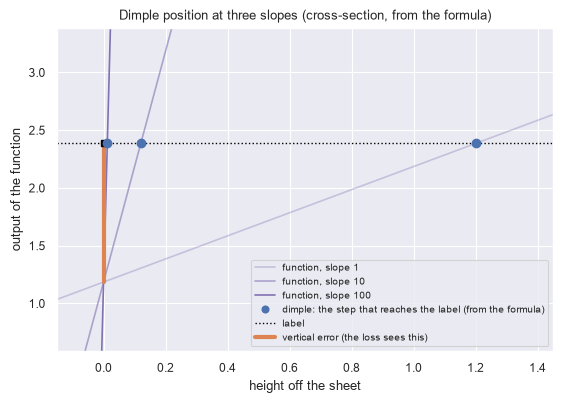

In [6]:
FIGURE_POSITION = 0.7
profile_value = float(evaluate_profile(FIGURE_POSITION))
FIGURE_LABEL = profile_value + 1.2
vertical_error_figure = abs(FIGURE_LABEL - profile_value)
heights = np.linspace(-0.15, 1.45, 400)
figure, axis = plt.subplots(figsize=(6.4, 4.2))
for slope, shade in zip((1.0, 10.0, 100.0), (0.35, 0.6, 1.0)):
    axis.plot(heights, evaluate_dimpled(FIGURE_POSITION, heights, slope), color=MODEL, alpha=shade, label=f"function, slope {slope:g}")
    dimple_position, dimple_height = make_dimple(FIGURE_POSITION, slope, FIGURE_LABEL)
    nearest_here = get_nearest_distance(FIGURE_POSITION, FIGURE_LABEL, slope)
    print(f"slope {slope:5.1f}: vertical error {vertical_error_figure:.4f}, step off the sheet (from the formula) {dimple_height:.4f}, "
          f"nearest distance (measured by search) {nearest_here:.4f}")
    axis.plot([dimple_height], [FIGURE_LABEL], "o", color=NEAREST, markersize=6, zorder=5)
axis.plot([], [], "o", color=NEAREST, label="dimple: the step that reaches the label (from the formula)")
axis.axhline(FIGURE_LABEL, color=DATA, linestyle=":", linewidth=1, label="label")
axis.plot([0.0, 0.0], [profile_value, FIGURE_LABEL], "-", color=VERTICAL, linewidth=3, label="vertical error (the loss sees this)")
axis.plot([0.0], [FIGURE_LABEL], "s", color=DATA, markersize=5)
axis.set_xlim(-0.15, 1.45)
axis.set_ylim(profile_value - 0.6, FIGURE_LABEL + 1.0)
axis.set_xlabel("height off the sheet")
axis.set_ylabel("output of the function")
axis.set_title("Dimple position at three slopes (cross-section, from the formula)")
axis.legend(loc="lower right", fontsize=7)
save_figure(figure, "46-step-off-the-sheet")
plt.show()

## Figure 2: the nearest distance against the slope, between the two bounds

For each of the 60 data points and the seven slopes (the numbers of claim 3), the distance divided by the vertical error. The loss sees
the vertical error, so its curve is flat at 1. The measured nearest distance (median, with the range over the 60 points) must stay
between the upper bound `1 / slope` and the lower bound `1 / sqrt(1 + (3.5 + slope)^2)`, which divided by the vertical error are the same for every point.

wrote book/figures/46-distance-against-slope.png


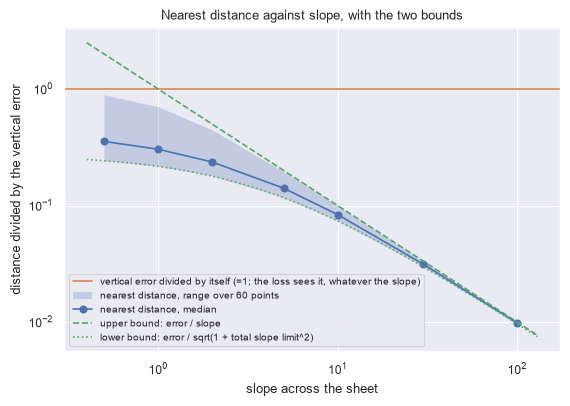

[by construction, cannot fail] figure 2 draws the arrays of claim 3, so its points lie between the drawn bounds if claim 3 passed


In [7]:
slope_grid = np.logspace(np.log10(0.4), np.log10(130.0), 200)
normalised = nearest / vertical_errors
figure, axis = plt.subplots(figsize=(6.4, 4.2))
axis.axhline(1.0, color=VERTICAL, label="vertical error divided by itself (=1; the loss sees it, whatever the slope)")
axis.fill_between(SLOPES, normalised.min(axis=1), normalised.max(axis=1), color=NEAREST, alpha=0.25, linewidth=0,
                  label="nearest distance, range over 60 points")
axis.plot(SLOPES, np.median(normalised, axis=1), "o-", color=NEAREST, label="nearest distance, median")
axis.plot(slope_grid, 1.0 / slope_grid, "--", color=BOUND, label="upper bound: error / slope")
axis.plot(slope_grid, 1.0 / np.sqrt(1 + (PROFILE_SLOPE_LIMIT + slope_grid) ** 2), ":", color=BOUND,
          label="lower bound: error / sqrt(1 + total slope limit^2)")
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("slope across the sheet")
axis.set_ylabel("distance divided by the vertical error")
axis.set_title("Nearest distance against slope, with the two bounds")
axis.legend(loc="lower left", fontsize=7)
save_figure(figure, "46-distance-against-slope")
plt.show()
slope_array = np.array(SLOPES)
note_by_construction("figure 2 draws the arrays of claim 3, so its points lie between the drawn bounds if claim 3 passed")